<a href="https://colab.research.google.com/github/sanya-6976/ml-interview-practise-dataset-projects/blob/main/Multi_Class_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (10578, 8)


,V1,V6,V10,V12,V13,V14,V15,Class
0,52.0,51.0,14.0,935.0,2.0,-1.0,0.0,1
1,53.0,232.0,29.0,32.0,1.0,-1.0,0.0,1
2,50.0,525.0,18.0,177.0,2.0,-1.0,0.0,1



--- Missing Values ---
0

--- Class Distribution (Counts & %) ---


,Count,Percentage (%)
Class,,
1,5289,50.0
2,5289,50.0


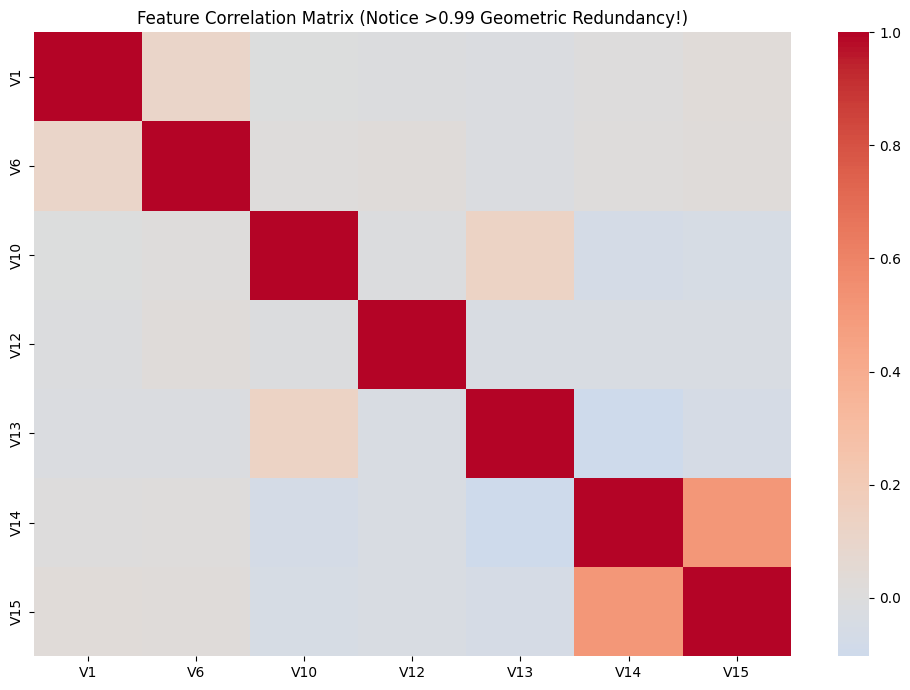

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

# 1. Load Dry Bean Dataset using its specific OpenML ID (44126)
beans = fetch_openml(data_id=44126, as_frame=True, parser='auto')
df = beans.frame

print("Shape:", df.shape)
display(df.head(3))

print("\n--- Missing Values ---")
print(df.isnull().sum().sum())

# 2. Check Multi-Class Distribution (7 classes)
print("\n--- Class Distribution (Counts & %) ---")
class_summary = pd.DataFrame({
    'Count': df['Class'].value_counts(),
    'Percentage (%)': (df['Class'].value_counts(normalize=True) * 100).round(2)
})
display(class_summary)

# 3. Quick Correlation Heatmap to spot collinear geometric features
plt.figure(figsize=(10, 7))
corr = df.drop(columns=['Class']).corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Feature Correlation Matrix (Notice >0.99 Geometric Redundancy!)')
plt.tight_layout()
plt.show()

Red squares mean "Two things move together": For example, if a bean is very wide, it is almost always very long too. Because these measurements tell us almost the same thing, we don't need both to understand the bean's size.
Blue squares mean "Opposites": When one measurement goes up, another one goes down.
Light/white squares mean "No connection": These measurements have nothing to do with each other.

Based on the correlation heatmap, we can draw the following key conclusions:

High Geometric Redundancy:

There is extreme collinearity (correlation values close to or at 1.0 or -1.0) between several shape and size features.

For example, area, perimeter, and major/minor axis lengths are naturally highly redundant. This tells us that we could likely reduce the dataset's dimensionality (using PCA or feature selection) without losing much information.

Feature Grouping:

You can notice blocks of highly correlated features (dark red or dark blue areas).

This indicates clusters of features that measure similar geometric attributes of the beans (e.g., overall size/scale vs. shape circularity/eccentricity).

Simplification Opportunities:

 Training machine learning models (especially linear ones) on all these features simultaneously might lead to multicollinearity issues, which can destabilize model coefficients.

 Selecting a subset of representative, less-correlated features would be a logical next step.

# **Label Encoding, Stratified Split & Multi-Class Baselines (LogisticRegression vs XGBoost)**

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss


le = LabelEncoder()
X = df.drop(columns=['Class'])
y = le.fit_transform(df['Class'])

print("Encoded Classes:", dict(enumerate(le.classes_)))

# 2. Stratified Train-Test Split FIRST (maintains exact 7-class proportions)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Compare Linear Baseline vs Non-Linear Gradient Boosting
models = {
    "Multinomial Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),

"XGBoost Multi-Class (softprob)": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='mlogloss'
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probas = model.predict_proba(X_test)  # Shape: (N_test, 7)

    print(f"\n--- {name} ---")
    print(f"Accuracy   : {accuracy_score(y_test, preds):.4f}")
    print(f"Macro-F1   : {f1_score(y_test, preds, average='macro'):.4f}")
    print(f"Log-Loss   : {log_loss(y_test, probas):.4f}")



Encoded Classes: {0: '1', 1: '2'}

--- Multinomial Logistic Regression ---
Accuracy   : 0.7443
Macro-F1   : 0.7439
Log-Loss   : 0.5372

--- XGBoost Multi-Class (softprob) ---
Accuracy   : 0.8043
Macro-F1   : 0.8043
Log-Loss   : 0.4370


We should choose the XGBoost model. It performs better across all metrics:

Higher Accuracy (80.43% vs 74.43%): It makes more correct predictions overall.

Better F1-Score (0.8043 vs 0.7439): It handles class predictions in a more balanced way.

Lower Log-Loss (0.4370 vs 0.5372): It is much more confident when making correct prediction

--- Per-Class Classification Report (XGBoost) ---
              precision    recall  f1-score   support

           1     0.8132    0.7902    0.8015      1058
           2     0.7960    0.8185    0.8071      1058

    accuracy                         0.8043      2116
   macro avg     0.8046    0.8043    0.8043      2116
weighted avg     0.8046    0.8043    0.8043      2116



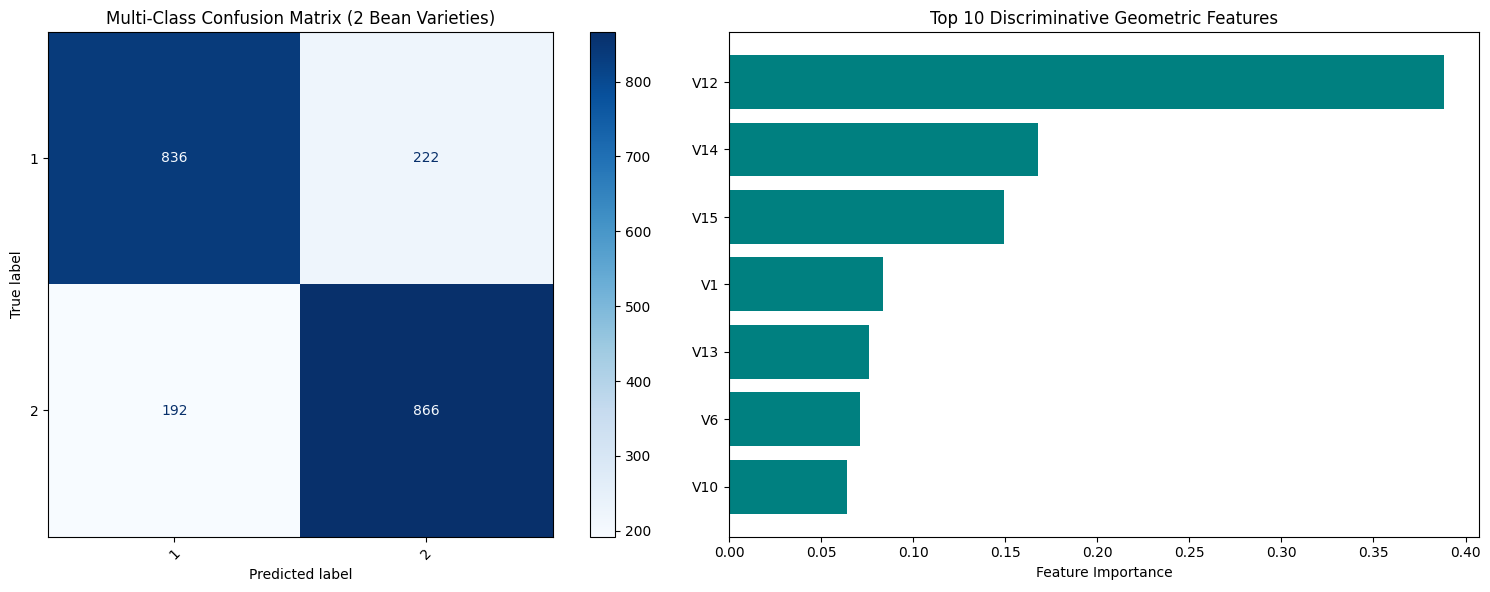

In [10]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Use the winning XGBoost Multi-Class model
xgb_multi = models["XGBoost Multi-Class (softprob)"]
y_pred_xgb = xgb_multi.predict(X_test)

# 1. Per-Class Precision, Recall, F1
print("--- Per-Class Classification Report (XGBoost) ---")
print(classification_report(y_test, y_pred_xgb, target_names=[str(c) for c in le.classes_], digits=4))

# 2. Multi-Class Confusion Matrix & Top Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_xgb,
    display_labels=le.classes_,
    cmap='Blues',
    xticks_rotation=45,
    ax=axes[0]
)
axes[0].set_title('Multi-Class Confusion Matrix (2 Bean Varieties)')

feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_multi.feature_importances_
}).sort_values(by='Importance', ascending=True).tail(10)

axes[1].barh(feat_imp['Feature'], feat_imp['Importance'], color='teal')
axes[1].set_title('Top 10 Discriminative Geometric Features')
axes[1].set_xlabel('Feature Importance')

plt.tight_layout()
plt.show()